# E3 — Thành viên 3: Interaction Graph Construction — FINAL



## 1. Mount Google Drive


In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


## 2. Imports và cấu hình

In [2]:
from pathlib import Path
from collections import Counter, defaultdict
import csv
import gzip
import hashlib
import json
import math
import os
import shutil

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

SEED = 42

# Canonical expected snapshot from Thành viên 1
EXPECTED_ACCOUNTS = 224_685
EXPECTED_LABEL_COUNTS = {0: 1_866, 1: 222_819}
EXPECTED_SPLIT_COUNTS = {
    'train': 157_279,
    'validation': 22_468,
    'test': 44_938,
}

# Neighbor data is NEVER force-merged by default.
STRICT_PROVENANCE = True
NEIGHBOR_MIN_TARGET_OVERLAP_TO_AUTO_MERGE = 0.95
NEIGHBOR_MIN_SPLIT_AGREEMENT_TO_AUTO_MERGE = 0.95

# Export full expanded neighbor GraphML can be large. Keep False unless needed.
EXPORT_EXPANDED_NEIGHBOR_GRAPHML = False

DRIVE_ROOT = Path('/content/drive/MyDrive')
OUT = DRIVE_ROOT / 'E3_member3_final_outputs'
DATA_OUT = OUT / 'data'
GRAPH_OUT = OUT / 'graphs'
FIG_OUT = OUT / 'figures'
AUDIT_OUT = OUT / 'audit'

for p in [OUT, DATA_OUT, GRAPH_OUT, FIG_OUT, AUDIT_OUT]:
    p.mkdir(parents=True, exist_ok=True)

print("Output root:", OUT)


Output root: /content/drive/MyDrive/E3_member3_final_outputs


## 3. Tìm file tự động

Notebook ưu tiên `MyDrive/MXH/processed`.

Nếu một file handoff Thành viên 1 nằm ở nơi khác trong My Drive, notebook tìm theo filename.


In [4]:
from pathlib import Path

# =========================================================
# ROOT
# =========================================================

DRIVE_ROOT = Path('/content/drive/MyDrive')


# =========================================================
# Helper
# =========================================================

def find_all(root: Path, filename: str):
    return list(root.rglob(filename))


def find_one(root: Path, filename: str, prefer_contains=None):
    matches = find_all(root, filename)

    if not matches:
        return None

    if prefer_contains:
        preferred = [
            p for p in matches
            if prefer_contains.lower() in str(p).lower()
        ]

        if preferred:
            matches = preferred

    if len(matches) > 1:
        print(f"⚠️ Có {len(matches)} file tên {filename}:")
        for p in matches:
            print("   ", p)

        print("→ Sử dụng:", matches[0])

    return matches[0]


# =========================================================
# 1. Honduras canonical data
# My Drive/MXH/processed
# =========================================================

PROCESSED = DRIVE_ROOT / 'MXH' / 'processed'

if not PROCESSED.exists():
    manifest_guess = find_one(
        DRIVE_ROOT,
        'honduras_account_manifest.csv',
        prefer_contains='processed'
    )

    if manifest_guess is not None:
        PROCESSED = manifest_guess.parent


BAD_FILE = (
    PROCESSED
    / 'honduras_bad_normalized.jsonl'
)

GOOD_FILE = (
    PROCESSED
    / 'honduras_good_normalized.jsonl'
)

MANIFEST_FILE = (
    PROCESSED
    / 'honduras_account_manifest.csv'
)

SPLITS_FILE = (
    PROCESSED
    / 'honduras_account_splits.csv'
)


# =========================================================
# 2. Thành viên 1 handoff
# Notebook hiện đã tìm được các file này trong
# SNA-GROUP3-final nên giữ cách search recursive
# =========================================================

TV1_METADATA = find_one(
    DRIVE_ROOT,
    'honduras_account_metadata.csv'
)

TV1_CONFIG = find_one(
    DRIVE_ROOT,
    'honduras_embedding_config.json'
)

TV1_VALIDATION = find_one(
    DRIVE_ROOT,
    'honduras_embedding_validation.json'
)


# =========================================================
# 3. Neighbor data
#
# QUAN TRỌNG:
# Folder "data" là shortcut trong My Drive.
# rglob có thể không đi xuyên shortcut,
# nên trỏ THẲNG path.
# =========================================================

NEIGHBOR_DATA_DIR = DRIVE_ROOT / 'data'

NEIGHBOR_FILE = (
    NEIGHBOR_DATA_DIR
    / 'neighbor_edges.jsonl'
)

SUPPORT_FILE = (
    NEIGHBOR_DATA_DIR
    / 'support_neighbors.jsonl'
)

EXTRACTION_SUMMARY = (
    NEIGHBOR_DATA_DIR
    / 'extraction_summary.json'
)


# =========================================================
# 4. FILE DETECTION
# =========================================================

files = {
    'BAD_FILE': BAD_FILE,
    'GOOD_FILE': GOOD_FILE,
    'MANIFEST_FILE': MANIFEST_FILE,
    'SPLITS_FILE': SPLITS_FILE,

    'TV1_METADATA': TV1_METADATA,
    'TV1_CONFIG': TV1_CONFIG,
    'TV1_VALIDATION': TV1_VALIDATION,

    'NEIGHBOR_FILE': NEIGHBOR_FILE,
    'SUPPORT_FILE': SUPPORT_FILE,
    'EXTRACTION_SUMMARY': EXTRACTION_SUMMARY,
}


print("\n========== FILE DETECTION ==========\n")

for name, path in files.items():

    exists = (
        path is not None
        and Path(path).is_file()
    )

    print(
        f"{'✅' if exists else '❌'} "
        f"{name:20s} -> {path}"
    )


# =========================================================
# 5. CHECK HONDURAS
# =========================================================

required_honduras = {
    'BAD_FILE': BAD_FILE,
    'GOOD_FILE': GOOD_FILE,
    'MANIFEST_FILE': MANIFEST_FILE,
    'SPLITS_FILE': SPLITS_FILE,
}

honduras_ok = True

for name, path in required_honduras.items():

    if not (
        path is not None
        and Path(path).is_file()
    ):
        honduras_ok = False
        print(
            f"❌ Thiếu Honduras file: "
            f"{name} -> {path}"
        )


if honduras_ok:
    print("\n✅ Honduras canonical data đã đủ.")
else:
    print("\n❌ Honduras canonical data chưa đủ.")


# =========================================================
# 6. CHECK TV1
# =========================================================

tv1_ok = all([
    TV1_METADATA is not None
    and Path(TV1_METADATA).is_file(),

    TV1_CONFIG is not None
    and Path(TV1_CONFIG).is_file(),

    TV1_VALIDATION is not None
    and Path(TV1_VALIDATION).is_file(),
])


if tv1_ok:
    print("✅ TV1 handoff đã đủ.")
else:
    print(
        "⚠️ TV1 handoff chưa đủ "
        "hoặc notebook chưa tìm thấy."
    )


# =========================================================
# 7. CHECK NEIGHBOR DATA
# =========================================================

neighbor_ok = all([
    NEIGHBOR_FILE.is_file(),
    SUPPORT_FILE.is_file(),
    EXTRACTION_SUMMARY.is_file(),
])


if neighbor_ok:
    print("✅ Neighbor data đã đủ.")
else:
    print("❌ Neighbor data chưa đủ.")

    print(
        "\nFolder notebook đang kiểm tra:"
    )
    print(NEIGHBOR_DATA_DIR)

    if NEIGHBOR_DATA_DIR.exists():
        print(
            "\nNội dung folder data:"
        )

        for p in NEIGHBOR_DATA_DIR.iterdir():
            print("   ", p.name)


# =========================================================
# 8. FINAL SUMMARY
# =========================================================

print("\n========== SUMMARY ==========\n")

if honduras_ok and tv1_ok and neighbor_ok:

    print(
        "✅ ĐỦ TOÀN BỘ INPUT — "
        "CÓ THỂ CHẠY NOTEBOOK FINAL."
    )

else:

    print(
        "❌ CHƯA ĐỦ / CHƯA ĐỌC ĐƯỢC "
        "MỘT SỐ INPUT."
    )


========== FILE DETECTION ==========

✅ BAD_FILE             -> /content/drive/MyDrive/MXH/processed/honduras_bad_normalized.jsonl
✅ GOOD_FILE            -> /content/drive/MyDrive/MXH/processed/honduras_good_normalized.jsonl
✅ MANIFEST_FILE        -> /content/drive/MyDrive/MXH/processed/honduras_account_manifest.csv
✅ SPLITS_FILE          -> /content/drive/MyDrive/MXH/processed/honduras_account_splits.csv
✅ TV1_METADATA         -> /content/drive/MyDrive/SNA-GROUP3-final/SNA-GROUP3-final/final/e2_outputs/data/honduras_account_metadata.csv
✅ TV1_CONFIG           -> /content/drive/MyDrive/SNA-GROUP3-final/SNA-GROUP3-final/final/e2_outputs/data/honduras_embedding_config.json
✅ TV1_VALIDATION       -> /content/drive/MyDrive/SNA-GROUP3-final/SNA-GROUP3-final/final/e2_outputs/data/honduras_embedding_validation.json
✅ NEIGHBOR_FILE        -> /content/drive/MyDrive/data/neighbor_edges.jsonl
✅ SUPPORT_FILE         -> /content/drive/MyDrive/data/support_neighbors.jsonl
✅ EXTRACTION_SUMMARY   -> 

## 4. Load canonical Honduras account mapping

Ưu tiên `honduras_account_metadata.csv` của Thành viên 1.

Nếu không tìm thấy, notebook reconstruct từ manifest + split table.

**ID luôn được giữ dạng string**, không convert float.


In [5]:
def as_id(x):
    if pd.isna(x):
        return ''
    s = str(x).strip()
    if s.endswith('.0') and s[:-2].isdigit():
        raise ValueError(f"ID có dạng float-like, không an toàn: {s}")
    if not s.isdigit():
        raise ValueError(f"ID không phải decimal string: {s!r}")
    return s

def normalize_split(x):
    s = str(x).strip().lower()
    return {'val': 'validation', 'dev': 'validation'}.get(s, s)

def load_manifest_and_splits(manifest_path, split_path):
    man = pd.read_csv(manifest_path, dtype=str)
    spl = pd.read_csv(split_path, dtype=str)

    id_col_m = next(c for c in ['account_id','user_id','userid'] if c in man.columns)
    id_col_s = next(c for c in ['account_id','user_id','userid'] if c in spl.columns)

    man['account_id'] = man[id_col_m].map(as_id)
    spl['account_id'] = spl[id_col_s].map(as_id)
    spl['split'] = spl['split'].map(normalize_split)

    man['label'] = man['label'].astype(int)
    cols = ['account_id','label']
    merged = man[cols].merge(
        spl[['account_id','split']],
        on='account_id',
        how='left',
        validate='one_to_one'
    )
    return merged

if TV1_METADATA and TV1_METADATA.is_file():
    metadata = pd.read_csv(TV1_METADATA, dtype=str)
    metadata['account_id'] = metadata['account_id'].map(as_id)
    metadata['label'] = metadata['label'].astype(int)
    metadata['split'] = metadata['split'].map(normalize_split)

    for c in ['row_index','eligible_tweet_count','selected_tweet_count']:
        if c in metadata.columns:
            metadata[c] = pd.to_numeric(metadata[c], errors='coerce')
else:
    metadata = load_manifest_and_splits(MANIFEST_FILE, SPLITS_FILE)
    metadata['row_index'] = np.arange(len(metadata))
    metadata['eligible_tweet_count'] = np.nan
    metadata['selected_tweet_count'] = np.nan

assert metadata['account_id'].is_unique
assert set(metadata['label'].unique()) <= {0,1}
assert set(metadata['split'].unique()) <= {'train','validation','test'}

print("Accounts:", len(metadata))
print("Labels:", metadata['label'].value_counts().sort_index().to_dict())
print("Splits:", metadata['split'].value_counts().to_dict())

assert len(metadata) == EXPECTED_ACCOUNTS, (
    f"Expected {EXPECTED_ACCOUNTS}, got {len(metadata)}"
)
assert metadata['label'].value_counts().sort_index().to_dict() == EXPECTED_LABEL_COUNTS
assert metadata['split'].value_counts().to_dict() == EXPECTED_SPLIT_COUNTS

canonical_ids = set(metadata['account_id'])
label_by_id = dict(zip(metadata['account_id'], metadata['label']))
split_by_id = dict(zip(metadata['account_id'], metadata['split']))

print("✅ Canonical Honduras mapping validated.")


Accounts: 224685
Labels: {0: 1866, 1: 222819}
Splits: {'train': 157279, 'test': 44938, 'validation': 22468}
✅ Canonical Honduras mapping validated.


## 5. Load handoff validation/config của Thành viên 1

Dùng để ghi provenance và duplicate policy vào report. Không dùng label/embedding để tạo interaction edge.


In [6]:
tv1_config = {}
tv1_validation = {}

if TV1_CONFIG and TV1_CONFIG.is_file():
    tv1_config = json.loads(TV1_CONFIG.read_text(encoding='utf-8'))
    print("TV1 duplicate policy:")
    print(tv1_config.get('duplicate_policy'))
else:
    print("⚠️ Không tìm thấy honduras_embedding_config.json trong My Drive.")

if TV1_VALIDATION and TV1_VALIDATION.is_file():
    tv1_validation = json.loads(TV1_VALIDATION.read_text(encoding='utf-8'))
    print("TV1 validation status:", tv1_validation.get('status'))
    print("TV1 embedding shape:", tv1_validation.get('shape'))
    print("TV1 zero vectors:", tv1_validation.get('zero_vector_rows'))


TV1 duplicate policy:
Keep first same-ID occurrence if account and stripped text agree, including metadata-only conflicts. Exclude all occurrences if account or text conflicts. Exclude whitespace-normalized exact text present in multiple splits and collapse repeated content within each account.
TV1 validation status: passed
TV1 embedding shape: [224685, 384]
TV1 zero vectors: 177861


## 6. Schema audit normalized JSONL

Schema kỳ vọng theo dữ liệu hiện tại gồm:

- `account_id`
- `tweet_id`
- `label`
- `text`
- `created_at`
- `retweet_tweet_id`
- `retweet_user_id`
- `reply_tweet_id`
- `reply_user_id`
- `quoted_tweet_id`

Notebook đọc cả Bad và Good để xác nhận thật, không giả định.


In [7]:
INTERACTION_FIELDS = [
    'retweet_tweet_id',
    'retweet_user_id',
    'reply_tweet_id',
    'reply_user_id',
    'quoted_tweet_id',
]

def jsonl_first(path):
    with path.open('r', encoding='utf-8-sig') as f:
        for line in f:
            if line.strip():
                return json.loads(line)
    return None

for p in [BAD_FILE, GOOD_FILE]:
    obj = jsonl_first(p)
    print("\n", p.name)
    print("keys =", sorted(obj.keys()))
    required = {
        'account_id','tweet_id','label','text','created_at',
        *INTERACTION_FIELDS
    }
    missing = required - set(obj)
    print("missing required fields:", sorted(missing))
    assert not missing, f"{p.name} thiếu field: {missing}"



 honduras_bad_normalized.jsonl
keys = ['account_creation_date', 'account_id', 'created_at', 'follower_count', 'following_count', 'hashtags', 'label', 'language', 'like_count', 'quote_count', 'quoted_tweet_id', 'reply_count', 'reply_tweet_id', 'reply_user_id', 'retweet_count', 'retweet_tweet_id', 'retweet_user_id', 'source', 'text', 'tweet_id', 'urls', 'user_mentions']
missing required fields: []

 honduras_good_normalized.jsonl
keys = ['account_creation_date', 'account_id', 'created_at', 'follower_count', 'following_count', 'hashtags', 'label', 'language', 'like_count', 'quote_count', 'quoted_tweet_id', 'reply_count', 'reply_tweet_id', 'reply_user_id', 'retweet_count', 'retweet_tweet_id', 'retweet_user_id', 'source', 'text', 'tweet_id', 'urls', 'user_mentions']
missing required fields: []


## 7. PASS 1 — Audit tweet IDs + tạo tweet→author mapping

Mục tiêu:

1. Đếm số dòng và coverage account.
2. Xác định duplicate tweet IDs.
3. Xác định **conflicting tweet IDs** nếu cùng tweet ID nhưng account/text khác.
4. Tạo mapping `tweet_id -> account_id` cho quote/reply/retweet lookup.
5. Đếm structured interaction fields non-null.

### Duplicate rule

- Same tweet ID + same account + same stripped text → giữ occurrence đầu.
- Same tweet ID nhưng account/text khác → loại toàn bộ occurrence của ID đó.

Đây là phần duplicate-ID policy phù hợp với handoff Thành viên 1.

> Cross-split exact-text removal của E2 là biện pháp chống leakage cho text embedding. Notebook E3 **không dùng text làm feature để tạo edge**, nên không xóa interaction metadata chỉ vì cùng text xuất hiện cross-split; việc này được ghi rõ trong report.


In [8]:
def text_signature(text):
    text = '' if text is None else str(text).strip()
    return hashlib.sha256(text.encode('utf-8')).digest()

def clean_optional_id(x):
    if x is None:
        return None
    s = str(x).strip()
    if not s or s.lower() in {'none','null','nan'}:
        return None
    # Preserve exact decimal IDs only
    if not s.isdigit():
        return None
    return s

tweet_first = {}          # tweet_id -> (account_id, text_hash)
tweet_author = {}         # tweet_id -> account_id for non-conflict first record
conflict_ids = set()
duplicate_occurrences = Counter()

pass1_stats = {
    'files': {},
    'nonnull_interaction_fields': Counter(),
    'accounts_seen': set(),
    'rows_total': 0,
    'rows_invalid': 0,
}

for path in [BAD_FILE, GOOD_FILE]:
    row_count = 0
    with path.open('r', encoding='utf-8-sig') as f:
        for line_no, line in enumerate(f, 1):
            if not line.strip():
                continue
            try:
                row = json.loads(line)
                account = as_id(row['account_id'])
                tweet_id = as_id(row['tweet_id'])
                label = int(row['label'])
            except Exception as exc:
                pass1_stats['rows_invalid'] += 1
                continue

            row_count += 1
            pass1_stats['rows_total'] += 1
            pass1_stats['accounts_seen'].add(account)

            if account not in canonical_ids:
                raise ValueError(
                    f"{path.name}:{line_no}: account {account} không có trong canonical metadata"
                )
            if label != label_by_id[account]:
                raise ValueError(
                    f"{path.name}:{line_no}: label mismatch account {account}"
                )

            for field in INTERACTION_FIELDS:
                if clean_optional_id(row.get(field)) is not None:
                    pass1_stats['nonnull_interaction_fields'][field] += 1

            sig = (account, text_signature(row.get('text')))
            if tweet_id in tweet_first:
                duplicate_occurrences[tweet_id] += 1
                if tweet_first[tweet_id] != sig:
                    conflict_ids.add(tweet_id)
            else:
                tweet_first[tweet_id] = sig
                tweet_author[tweet_id] = account

    pass1_stats['files'][path.name] = row_count
    print(path.name, "rows =", f"{row_count:,}")

# Remove author mapping for conflicting tweet IDs.
for tid in conflict_ids:
    tweet_author.pop(tid, None)

pass1_summary = {
    'rows_total': pass1_stats['rows_total'],
    'rows_invalid': pass1_stats['rows_invalid'],
    'files': pass1_stats['files'],
    'accounts_seen': len(pass1_stats['accounts_seen']),
    'canonical_accounts': len(canonical_ids),
    'duplicate_tweet_ids': len(duplicate_occurrences),
    'duplicate_extra_rows': int(sum(duplicate_occurrences.values())),
    'conflicting_tweet_ids': len(conflict_ids),
    'safe_tweet_author_mappings': len(tweet_author),
    'nonnull_interaction_fields': dict(pass1_stats['nonnull_interaction_fields']),
}
print(json.dumps(pass1_summary, ensure_ascii=False, indent=2))

assert pass1_stats['accounts_seen'] == canonical_ids, (
    "Normalized JSONL account coverage không khớp canonical metadata"
)


honduras_bad_normalized.jsonl rows = 137,252
honduras_good_normalized.jsonl rows = 1,125,578
{
  "rows_total": 1262830,
  "rows_invalid": 0,
  "files": {
    "honduras_bad_normalized.jsonl": 137252,
    "honduras_good_normalized.jsonl": 1125578
  },
  "accounts_seen": 224685,
  "canonical_accounts": 224685,
  "duplicate_tweet_ids": 5649,
  "duplicate_extra_rows": 8256,
  "conflicting_tweet_ids": 390,
  "safe_tweet_author_mappings": 1254184,
  "nonnull_interaction_fields": {}
}


## 8. Export `tweet_id_user_mapping.csv`

Chỉ export tweet IDs không conflict.


In [9]:
tweet_map_path = DATA_OUT / 'tweet_id_user_mapping.csv'

with tweet_map_path.open('w', encoding='utf-8', newline='') as f:
    w = csv.writer(f)
    w.writerow(['tweet_id','account_id'])
    for tweet_id, account_id in sorted(tweet_author.items(), key=lambda x: int(x[0])):
        w.writerow([tweet_id, account_id])

print("Saved:", tweet_map_path)
print("Rows:", len(tweet_author))


Saved: /content/drive/MyDrive/E3_member3_final_outputs/data/tweet_id_user_mapping.csv
Rows: 1254184


## 9. PASS 2 — Extract structured retweet / reply / quote events

### Target resolution

- Retweet: ưu tiên `retweet_user_id`, fallback lookup `retweet_tweet_id`.
- Reply: ưu tiên `reply_user_id`, fallback lookup `reply_tweet_id`.
- Quote: lookup `quoted_tweet_id -> author`.
- Không parse text `RT @...`.
- Timestamp = `created_at` của tweet thực hiện interaction.
- Skip self-loop.
- Giữ external target IDs trong event log, nhưng **official Honduras graph chỉ dùng cạnh mà cả hai đầu là canonical Honduras accounts**.


In [10]:
def resolve_target(row, user_field=None, tweet_field=None):
    if user_field:
        uid = clean_optional_id(row.get(user_field))
        if uid is not None:
            return uid, 'structured_user_id'

    if tweet_field:
        tid = clean_optional_id(row.get(tweet_field))
        if tid is not None:
            author = tweet_author.get(tid)
            if author is not None:
                return author, 'tweet_id_lookup'

    return None, None

event_path = DATA_OUT / 'interaction_events.csv.gz'

edge_aggr = defaultdict(lambda: {
    'retweet_count': 0,
    'reply_count': 0,
    'quote_count': 0,
    'first_timestamp': None,
    'last_timestamp': None,
    'external_target_count': 0,
})

structured_stats = Counter()
seen_safe_tweet_ids = set()

with gzip.open(event_path, 'wt', encoding='utf-8', newline='') as gz:
    w = csv.writer(gz)
    w.writerow([
        'source','target','interaction_type','timestamp',
        'source_tweet_id','target_resolution',
        'source_is_honduras','target_is_honduras'
    ])

    for path in [BAD_FILE, GOOD_FILE]:
        with path.open('r', encoding='utf-8-sig') as f:
            for line_no, line in enumerate(f, 1):
                if not line.strip():
                    continue
                row = json.loads(line)

                source = as_id(row['account_id'])
                tweet_id = as_id(row['tweet_id'])

                # Duplicate/conflict handling.
                if tweet_id in conflict_ids:
                    structured_stats['rows_skipped_conflict_id'] += 1
                    continue
                if tweet_id in seen_safe_tweet_ids:
                    structured_stats['rows_skipped_duplicate_id'] += 1
                    continue
                seen_safe_tweet_ids.add(tweet_id)

                timestamp = row.get('created_at')

                candidates = [
                    (
                        'retweet',
                        *resolve_target(
                            row,
                            user_field='retweet_user_id',
                            tweet_field='retweet_tweet_id'
                        )
                    ),
                    (
                        'reply',
                        *resolve_target(
                            row,
                            user_field='reply_user_id',
                            tweet_field='reply_tweet_id'
                        )
                    ),
                    (
                        'quote',
                        *resolve_target(
                            row,
                            user_field=None,
                            tweet_field='quoted_tweet_id'
                        )
                    ),
                ]

                for interaction_type, target, resolution in candidates:
                    if target is None:
                        continue

                    structured_stats[f'{interaction_type}_resolved'] += 1

                    if source == target:
                        structured_stats['self_loops_removed'] += 1
                        continue

                    source_in = source in canonical_ids
                    target_in = target in canonical_ids
                    if not target_in:
                        structured_stats[f'{interaction_type}_external_target'] += 1

                    w.writerow([
                        source, target, interaction_type, timestamp,
                        tweet_id, resolution,
                        source_in, target_in
                    ])

                    # Official Graph A only aggregates canonical-to-canonical relations.
                    if source_in and target_in:
                        key = (source, target)
                        rec = edge_aggr[key]
                        rec[f'{interaction_type}_count'] += 1

                        if timestamp is not None:
                            try:
                                ts = int(timestamp)
                                rec['first_timestamp'] = (
                                    ts if rec['first_timestamp'] is None
                                    else min(rec['first_timestamp'], ts)
                                )
                                rec['last_timestamp'] = (
                                    ts if rec['last_timestamp'] is None
                                    else max(rec['last_timestamp'], ts)
                                )
                            except Exception:
                                structured_stats['invalid_timestamp'] += 1

print("Structured interaction stats:")
print(json.dumps(dict(structured_stats), ensure_ascii=False, indent=2))
print("Official canonical directed pair count:", len(edge_aggr))
print("Saved events:", event_path)


Structured interaction stats:
{
  "rows_skipped_conflict_id": 1364,
  "rows_skipped_duplicate_id": 7282
}
Official canonical directed pair count: 0
Saved events: /content/drive/MyDrive/E3_member3_final_outputs/data/interaction_events.csv.gz


## 10. Export canonical structured interaction edges

`interaction_edges_structured.csv` là edge list đúng theo retweet/reply/quote structured metadata.

Một row = một directed source→target pair.

`weight = retweet_count + reply_count + quote_count`.


In [11]:
structured_edge_rows = []

for (source, target), rec in edge_aggr.items():
    total = (
        rec['retweet_count']
        + rec['reply_count']
        + rec['quote_count']
    )
    structured_edge_rows.append({
        'source': source,
        'target': target,
        'retweet_count': rec['retweet_count'],
        'reply_count': rec['reply_count'],
        'quote_count': rec['quote_count'],
        'weight': total,
        'first_timestamp': rec['first_timestamp'],
        'last_timestamp': rec['last_timestamp'],
        'edge_source': 'normalized_structured_interaction',
    })

structured_edges_df = pd.DataFrame(
    structured_edge_rows,
    columns=[
        'source','target',
        'retweet_count','reply_count','quote_count',
        'weight','first_timestamp','last_timestamp','edge_source'
    ]
)

structured_edges_path = DATA_OUT / 'interaction_edges_structured.csv'
structured_edges_df.to_csv(structured_edges_path, index=False)

print("Structured canonical edges:", len(structured_edges_df))
display(structured_edges_df.head())
print("Saved:", structured_edges_path)


Structured canonical edges: 0


,source,target,retweet_count,reply_count,quote_count,weight,first_timestamp,last_timestamp,edge_source


Saved: /content/drive/MyDrive/E3_member3_final_outputs/data/interaction_edges_structured.csv


## 11. Audit neighbor data mới

Nguồn mới **không được merge tự động** chỉ vì có cùng định dạng ID.

Notebook kiểm tra:

1. target account overlap với canonical Honduras
2. all-neighbor overlap với canonical Honduras
3. split agreement trên target IDs trùng nhau
4. coverage external support

Hiện snapshot trước khi tạo notebook cho thấy overlap rất thấp; notebook sẽ tự tính lại trên Drive của bạn.


In [12]:
neighbor_audit = {
    'available': False,
    'auto_merge_allowed': False,
}

neighbor_honduras_edges = set()
neighbor_expanded_edges = set()
neighbor_target_ids = set()
neighbor_all_ids = set()
neighbor_split_by_target = {}

if NEIGHBOR_FILE and NEIGHBOR_FILE.is_file():
    neighbor_audit['available'] = True

    parse_errors = 0
    raw_refs = 0

    with NEIGHBOR_FILE.open('r', encoding='utf-8') as f:
        for line_no, line in enumerate(f, 1):
            if not line.strip():
                continue
            try:
                row = json.loads(line)
                a = as_id(row['account_id'])
                split = normalize_split(row.get('split',''))
                following = [
                    clean_optional_id(x)
                    for x in (row.get('following') or [])
                ]
                follower = [
                    clean_optional_id(x)
                    for x in (row.get('follower') or [])
                ]
                following = [x for x in following if x]
                follower = [x for x in follower if x]
            except Exception:
                parse_errors += 1
                continue

            neighbor_target_ids.add(a)
            neighbor_split_by_target[a] = split
            neighbor_all_ids.add(a)

            # following means a -> b
            for b in following:
                raw_refs += 1
                neighbor_all_ids.add(b)
                if a != b:
                    neighbor_expanded_edges.add((a,b))
                    if a in canonical_ids and b in canonical_ids:
                        neighbor_honduras_edges.add((a,b))

            # follower means b -> a
            for b in follower:
                raw_refs += 1
                neighbor_all_ids.add(b)
                if a != b:
                    neighbor_expanded_edges.add((b,a))
                    if a in canonical_ids and b in canonical_ids:
                        neighbor_honduras_edges.add((b,a))

    target_overlap = neighbor_target_ids & canonical_ids
    all_overlap = neighbor_all_ids & canonical_ids

    split_match = 0
    split_compared = 0
    for uid in target_overlap:
        ns = neighbor_split_by_target.get(uid)
        cs = split_by_id.get(uid)
        if ns in {'train','validation','test'} and cs:
            split_compared += 1
            split_match += int(ns == cs)

    target_overlap_ratio = (
        len(target_overlap) / len(neighbor_target_ids)
        if neighbor_target_ids else 0.0
    )
    split_agreement = (
        split_match / split_compared
        if split_compared else 0.0
    )

    neighbor_audit.update({
        'parse_errors': parse_errors,
        'raw_relation_references': raw_refs,
        'neighbor_target_accounts': len(neighbor_target_ids),
        'target_accounts_in_honduras': len(target_overlap),
        'target_overlap_ratio': target_overlap_ratio,
        'all_neighbor_or_target_ids': len(neighbor_all_ids),
        'all_ids_in_honduras': len(all_overlap),
        'canonical_honduras_overlap_edges': len(neighbor_honduras_edges),
        'expanded_directed_edges': len(neighbor_expanded_edges),
        'split_compared': split_compared,
        'split_matches': split_match,
        'split_agreement': split_agreement,
    })

    neighbor_audit['auto_merge_allowed'] = (
        target_overlap_ratio >= NEIGHBOR_MIN_TARGET_OVERLAP_TO_AUTO_MERGE
        and split_agreement >= NEIGHBOR_MIN_SPLIT_AGREEMENT_TO_AUTO_MERGE
    )

print(json.dumps(neighbor_audit, ensure_ascii=False, indent=2))


{
  "available": true,
  "auto_merge_allowed": false,
  "parse_errors": 0,
  "raw_relation_references": 208716,
  "neighbor_target_accounts": 11826,
  "target_accounts_in_honduras": 93,
  "target_overlap_ratio": 0.007864028411973617,
  "all_neighbor_or_target_ids": 191582,
  "all_ids_in_honduras": 897,
  "canonical_honduras_overlap_edges": 146,
  "expanded_directed_edges": 208381,
  "split_compared": 93,
  "split_matches": 45,
  "split_agreement": 0.4838709677419355
}


## 12. Audit `support_neighbors.jsonl`

Không gán label/split Honduras cho external support accounts.

File này chỉ dùng để kiểm tra coverage và metadata hỗ trợ cho expanded neighbor graph.


In [25]:
support_audit = {
    'available': False,
}

support_records = {}

if SUPPORT_FILE and SUPPORT_FILE.is_file():

    support_audit['available'] = True

    parse_errors = 0

    with SUPPORT_FILE.open(
        'r',
        encoding='utf-8'
    ) as f:

        for line_no, line in enumerate(f, 1):

            if not line.strip():
                continue

            try:
                row = json.loads(line)

                uid = as_id(row['ID'])

                profile = (
                    row.get('profile')
                    or {}
                )

                tweets = (
                    row.get('tweets')
                    or []
                )

            except Exception:
                parse_errors += 1
                continue

            support_records[uid] = {
                'screen_name':
                    profile.get('screen_name'),

                'name':
                    profile.get('name'),

                'followers_count':
                    profile.get('followers_count'),

                'friends_count':
                    profile.get('friends_count'),

                'statuses_count':
                    profile.get('statuses_count'),

                'support_tweet_count':
                    len(tweets),
            }


    # =====================================================
    # IMPORTANT:
    # External neighbor ở đây nghĩa là:
    # xuất hiện trong following/follower
    # nhưng KHÔNG phải target account của neighbor dataset.
    #
    # Không được dùng:
    # neighbor_all_ids - canonical_ids
    #
    # vì cách đó sẽ tính cả target account của dataset khác
    # thành "missing support account".
    # =====================================================

    external_neighbor_ids = (
        neighbor_all_ids
        - neighbor_target_ids
    )


    support_ids = set(
        support_records.keys()
    )


    missing_support = (
        external_neighbor_ids
        - support_ids
    )

    extra_support = (
        support_ids
        - external_neighbor_ids
    )


    support_audit.update({
        'parse_errors':
            parse_errors,

        'support_accounts_found':
            len(support_records),

        'external_neighbor_ids':
            len(external_neighbor_ids),

        'external_neighbor_support_missing':
            len(missing_support),

        'extra_support_records':
            len(extra_support),

        'non_honduras_neighbor_target_accounts':
            len(
                neighbor_target_ids
                - canonical_ids
            ),
    })


print(
    json.dumps(
        support_audit,
        ensure_ascii=False,
        indent=2
    )
)

{
  "available": true,
  "parse_errors": 0,
  "support_accounts_found": 179756,
  "external_neighbor_ids": 179756,
  "external_neighbor_support_missing": 0,
  "extra_support_records": 0,
  "non_honduras_neighbor_target_accounts": 11733
}


## 13. Export neighbor overlap / expanded edge lists

Hai file riêng biệt:

- `neighbor_edges_honduras_overlap.csv`: chỉ edge mà cả source/target là canonical Honduras.
- `neighbor_edges_expanded.csv`: toàn bộ follow/follower relations từ Drive mới.

**Không gọi expanded graph là Honduras graph.**


In [26]:
neighbor_overlap_path = DATA_OUT / 'neighbor_edges_honduras_overlap.csv'
neighbor_expanded_path = DATA_OUT / 'neighbor_edges_expanded.csv'

pd.DataFrame(
    sorted(neighbor_honduras_edges),
    columns=['source','target']
).assign(edge_source='neighbor_follow_overlap').to_csv(
    neighbor_overlap_path, index=False
)

pd.DataFrame(
    sorted(neighbor_expanded_edges),
    columns=['source','target']
).assign(edge_source='neighbor_follow_expanded').to_csv(
    neighbor_expanded_path, index=False
)

print("Saved:", neighbor_overlap_path)
print("Saved:", neighbor_expanded_path)


Saved: /content/drive/MyDrive/E3_member3_final_outputs/data/neighbor_edges_honduras_overlap.csv
Saved: /content/drive/MyDrive/E3_member3_final_outputs/data/neighbor_edges_expanded.csv


## 14. Quyết định merge chính thức

### Strict provenance mode

Neighbor data chỉ được auto-merge vào official Graph A nếu:

- >=95% target accounts map vào canonical Honduras
- >=95% split agreement trên các ID có thể so sánh

Nếu không đạt:
- neighbor data vẫn được export/audit
- official Graph A **không merge nguồn đó**
- report ghi `BLOCKED_BY_PROVENANCE`

Điều này tránh tạo graph sai dataset.


In [27]:
if not neighbor_audit['available']:
    merge_neighbor = False
    merge_reason = 'neighbor_data_unavailable'
elif neighbor_audit.get('auto_merge_allowed'):
    merge_neighbor = True
    merge_reason = 'provenance_threshold_passed'
else:
    merge_neighbor = False
    merge_reason = 'provenance_threshold_failed'

if not STRICT_PROVENANCE and neighbor_audit['available']:
    print("⚠️ STRICT_PROVENANCE=False: có thể force merge — không khuyến nghị.")
    merge_neighbor = True
    merge_reason = 'forced_by_user_config'

print("merge_neighbor =", merge_neighbor)
print("reason =", merge_reason)


merge_neighbor = False
reason = provenance_threshold_failed


## 15. Build official `interaction_edges.csv`

Official edges:

1. structured retweet/reply/quote canonical edges
2. neighbor overlap **chỉ khi provenance audit pass**

Nếu structured interactions = 0 và neighbor provenance fail, notebook vẫn xuất graph/node table trung thực nhưng report sẽ ghi **Graph A chưa đủ evidence**.


In [28]:
official = {}

# Start with structured edges
for row in structured_edges_df.to_dict('records'):
    key = (row['source'], row['target'])
    official[key] = {
        'source': row['source'],
        'target': row['target'],
        'retweet_count': int(row['retweet_count']),
        'reply_count': int(row['reply_count']),
        'quote_count': int(row['quote_count']),
        'neighbor_follow_count': 0,
        'first_timestamp': row['first_timestamp'],
        'last_timestamp': row['last_timestamp'],
        'sources': {'normalized_structured_interaction'},
    }

if merge_neighbor:
    for s, t in neighbor_honduras_edges:
        key = (s,t)
        if key not in official:
            official[key] = {
                'source': s,
                'target': t,
                'retweet_count': 0,
                'reply_count': 0,
                'quote_count': 0,
                'neighbor_follow_count': 0,
                'first_timestamp': None,
                'last_timestamp': None,
                'sources': set(),
            }
        official[key]['neighbor_follow_count'] += 1
        official[key]['sources'].add('neighbor_follow_overlap')

official_rows = []
for rec in official.values():
    weight = (
        rec['retweet_count']
        + rec['reply_count']
        + rec['quote_count']
        + rec['neighbor_follow_count']
    )
    official_rows.append({
        'source': rec['source'],
        'target': rec['target'],
        'retweet_count': rec['retweet_count'],
        'reply_count': rec['reply_count'],
        'quote_count': rec['quote_count'],
        'neighbor_follow_count': rec['neighbor_follow_count'],
        'weight': weight,
        'first_timestamp': rec['first_timestamp'],
        'last_timestamp': rec['last_timestamp'],
        'edge_sources': '+'.join(sorted(rec['sources'])),
    })

interaction_edges = pd.DataFrame(
    official_rows,
    columns=[
        'source','target',
        'retweet_count','reply_count','quote_count',
        'neighbor_follow_count','weight',
        'first_timestamp','last_timestamp','edge_sources'
    ]
)

official_edges_path = DATA_OUT / 'interaction_edges.csv'
interaction_edges.to_csv(official_edges_path, index=False)

print("Official Graph A directed edges:", len(interaction_edges))
display(interaction_edges.head())
print("Saved:", official_edges_path)


Official Graph A directed edges: 0


,source,target,retweet_count,reply_count,quote_count,neighbor_follow_count,weight,first_timestamp,last_timestamp,edge_sources


Saved: /content/drive/MyDrive/E3_member3_final_outputs/data/interaction_edges.csv


## 16. Build `nodes.csv`

Giữ **toàn bộ 224.685 Honduras accounts** kể cả isolate.

Không thêm external neighbor vào official `nodes.csv`.

External support metadata chỉ nằm trong auxiliary report/graph.


In [29]:
degree_in = Counter()
degree_out = Counter()
strength_in = Counter()
strength_out = Counter()

for row in interaction_edges.itertuples(index=False):
    degree_out[row.source] += 1
    degree_in[row.target] += 1
    strength_out[row.source] += int(row.weight)
    strength_in[row.target] += int(row.weight)

nodes = metadata.copy()

nodes['in_degree'] = nodes['account_id'].map(degree_in).fillna(0).astype(int)
nodes['out_degree'] = nodes['account_id'].map(degree_out).fillna(0).astype(int)
nodes['degree_total_directed'] = nodes['in_degree'] + nodes['out_degree']
nodes['in_strength'] = nodes['account_id'].map(strength_in).fillna(0).astype(int)
nodes['out_strength'] = nodes['account_id'].map(strength_out).fillna(0).astype(int)
nodes['is_isolate'] = nodes['degree_total_directed'].eq(0)

nodes_path = DATA_OUT / 'nodes.csv'
nodes.to_csv(nodes_path, index=False)

print("nodes =", len(nodes))
print("isolates =", int(nodes['is_isolate'].sum()))
display(nodes.head())


nodes = 224685
isolates = 224685


,row_index,account_id,label,split,eligible_tweet_count,selected_tweet_count,in_degree,out_degree,degree_total_directed,in_strength,out_strength,is_isolate
0,0,1000005746078216193,1,train,1,1,0,0,0,0,0,True
1,1,1000006078409650177,1,train,0,0,0,0,0,0,0,True
2,2,100001435,1,test,0,0,0,0,0,0,0,True
3,3,100001645,1,train,0,0,0,0,0,0,0,True
4,4,1000017357534883840,1,train,0,0,0,0,0,0,0,True


## 17. Graph export

- `interaction_graph_directed.graphml`: canonical directed Graph A
- `coordination_graph.graphml`: undirected weighted projection cho Người 4 / community analysis

Undirected pair weight = tổng weight của cả hai hướng nếu cùng pair.


In [30]:
Gd = nx.DiGraph()

for row in nodes.itertuples(index=False):
    attrs = {
        'label': int(row.label),
        'split': str(row.split),
        'is_isolate': bool(row.is_isolate),
    }
    if hasattr(row, 'selected_tweet_count') and pd.notna(row.selected_tweet_count):
        attrs['selected_tweet_count'] = int(row.selected_tweet_count)
    Gd.add_node(row.account_id, **attrs)

for row in interaction_edges.itertuples(index=False):
    Gd.add_edge(
        row.source,
        row.target,
        weight=int(row.weight),
        retweet_count=int(row.retweet_count),
        reply_count=int(row.reply_count),
        quote_count=int(row.quote_count),
        neighbor_follow_count=int(row.neighbor_follow_count),
        edge_sources=str(row.edge_sources),
    )

Gu = nx.Graph()
for n, attrs in Gd.nodes(data=True):
    Gu.add_node(n, **attrs)

for s, t, attrs in Gd.edges(data=True):
    if Gu.has_edge(s,t):
        Gu[s][t]['weight'] += int(attrs['weight'])
        Gu[s][t]['directed_relation_count'] += 1
    else:
        Gu.add_edge(
            s, t,
            weight=int(attrs['weight']),
            directed_relation_count=1,
        )

directed_path = GRAPH_OUT / 'interaction_graph_directed.graphml'
coordination_path = GRAPH_OUT / 'coordination_graph.graphml'

nx.write_graphml(Gd, directed_path)
nx.write_graphml(Gu, coordination_path)

print("Directed:", Gd.number_of_nodes(), Gd.number_of_edges())
print("Undirected:", Gu.number_of_nodes(), Gu.number_of_edges())
print("Saved:", directed_path)
print("Saved:", coordination_path)


Directed: 224685 0
Undirected: 224685 0
Saved: /content/drive/MyDrive/E3_member3_final_outputs/graphs/interaction_graph_directed.graphml
Saved: /content/drive/MyDrive/E3_member3_final_outputs/graphs/coordination_graph.graphml


## 18. Auxiliary expanded neighbor graph

Nguồn này được giữ riêng vì provenance không được mặc định là Honduras.

Export GraphML chỉ khi `EXPORT_EXPANDED_NEIGHBOR_GRAPHML=True`.


In [31]:
expanded_neighbor_report = {}

if neighbor_audit['available']:
    expanded_nodes = neighbor_all_ids | canonical_ids

    expanded_neighbor_report = {
        'nodes_if_union_with_honduras': len(expanded_nodes),
        'neighbor_directed_edges': len(neighbor_expanded_edges),
        'external_support_profiles': len(support_records),
        'graphml_exported': bool(EXPORT_EXPANDED_NEIGHBOR_GRAPHML),
    }

    if EXPORT_EXPANDED_NEIGHBOR_GRAPHML:
        Gx = nx.DiGraph()

        for uid in canonical_ids:
            Gx.add_node(
                uid,
                node_type='honduras',
                label=int(label_by_id[uid]),
                split=split_by_id[uid]
            )

        for uid in neighbor_all_ids - canonical_ids:
            meta = support_records.get(uid, {})
            Gx.add_node(
                uid,
                node_type='external_support',
                screen_name=str(meta.get('screen_name') or ''),
            )

        for s,t in neighbor_expanded_edges:
            if s != t:
                Gx.add_edge(s,t,weight=1,edge_source='neighbor_follow_expanded')

        expanded_graph_path = GRAPH_OUT / 'neighbor_expanded_graph.graphml'
        nx.write_graphml(Gx, expanded_graph_path)
        print("Saved:", expanded_graph_path)

print(json.dumps(expanded_neighbor_report, ensure_ascii=False, indent=2))


{
  "nodes_if_union_with_honduras": 415370,
  "neighbor_directed_edges": 208381,
  "external_support_profiles": 179756,
  "graphml_exported": false
}


## 19. Graph statistics

Metrics không dùng label để tạo graph. Label chỉ được giữ làm metadata downstream.


In [32]:
isolates = list(nx.isolates(Gu))
components = list(nx.connected_components(Gu))
component_sizes = sorted((len(c) for c in components), reverse=True)
degrees = [d for _,d in Gu.degree()]

graph_metrics = {
    'canonical_nodes': Gu.number_of_nodes(),
    'directed_edges': Gd.number_of_edges(),
    'undirected_edges': Gu.number_of_edges(),
    'isolates': len(isolates),
    'isolate_rate': len(isolates) / Gu.number_of_nodes() if Gu.number_of_nodes() else 0,
    'connected_components': len(components),
    'largest_connected_component': component_sizes[0] if component_sizes else 0,
    'mean_undirected_degree': float(np.mean(degrees)) if degrees else 0.0,
    'median_undirected_degree': float(np.median(degrees)) if degrees else 0.0,
    'max_undirected_degree': int(max(degrees)) if degrees else 0,
    'labels_used_for_edge_construction': False,
}

print(json.dumps(graph_metrics, ensure_ascii=False, indent=2))


{
  "canonical_nodes": 224685,
  "directed_edges": 0,
  "undirected_edges": 0,
  "isolates": 224685,
  "isolate_rate": 1.0,
  "connected_components": 224685,
  "largest_connected_component": 1,
  "mean_undirected_degree": 0.0,
  "median_undirected_degree": 0.0,
  "max_undirected_degree": 0,
  "labels_used_for_edge_construction": false
}


## 20. Readiness / handoff status

Notebook không tự tuyên bố READY nếu không có đủ evidence.

- Nếu official graph có edge → `READY_FOR_MEMBER4`
- Nếu 0 edge → `BLOCKED_NO_VALIDATED_INTERACTION_EDGES`

Neighbor data provenance fail được ghi riêng, không che lấp.


In [33]:
if len(interaction_edges) > 0:
    handoff_status = 'READY_FOR_MEMBER4'
else:
    handoff_status = 'BLOCKED_NO_VALIDATED_INTERACTION_EDGES'

data_readiness = {
    'handoff_status': handoff_status,
    'canonical_honduras_accounts': len(canonical_ids),
    'structured_interaction_field_nonnull_counts':
        pass1_summary['nonnull_interaction_fields'],
    'structured_interaction_stats': dict(structured_stats),
    'structured_canonical_edges': len(structured_edges_df),
    'neighbor_audit': neighbor_audit,
    'neighbor_support_audit': support_audit,
    'neighbor_merged_into_official_graph': merge_neighbor,
    'neighbor_merge_reason': merge_reason,
    'official_directed_edges': len(interaction_edges),
    'official_undirected_edges': Gu.number_of_edges(),
    'policy': {
        'parse_RT_at_text': False,
        'labels_used_for_edges': False,
        'canonical_node_universe': '224,685 Honduras accounts',
        'external_support_labels_assigned': False,
        'strict_provenance': STRICT_PROVENANCE,
    }
}

readiness_path = AUDIT_OUT / 'data_readiness.json'
readiness_path.write_text(
    json.dumps(data_readiness, ensure_ascii=False, indent=2),
    encoding='utf-8'
)

print(json.dumps(data_readiness, ensure_ascii=False, indent=2))
print("Saved:", readiness_path)


{
  "handoff_status": "BLOCKED_NO_VALIDATED_INTERACTION_EDGES",
  "canonical_honduras_accounts": 224685,
  "structured_interaction_field_nonnull_counts": {},
  "structured_interaction_stats": {
    "rows_skipped_conflict_id": 1364,
    "rows_skipped_duplicate_id": 7282
  },
  "structured_canonical_edges": 0,
  "neighbor_audit": {
    "available": true,
    "auto_merge_allowed": false,
    "parse_errors": 0,
    "raw_relation_references": 208716,
    "neighbor_target_accounts": 11826,
    "target_accounts_in_honduras": 93,
    "target_overlap_ratio": 0.007864028411973617,
    "all_neighbor_or_target_ids": 191582,
    "all_ids_in_honduras": 897,
    "canonical_honduras_overlap_edges": 146,
    "expanded_directed_edges": 208381,
    "split_compared": 93,
    "split_matches": 45,
    "split_agreement": 0.4838709677419355
  },
  "neighbor_support_audit": {
    "available": true,
    "parse_errors": 0,
    "support_accounts_found": 179756,
    "external_neighbor_ids": 179756,
    "external_n

## 21. Save `graph_data_report.json`

Report chứa:

- canonical mapping
- duplicate/conflict audit
- interaction field coverage
- neighbor provenance audit
- graph statistics
- handoff status


In [34]:
report = {
    'member': 3,
    'task': 'E3 Interaction Graph Construction',
    'canonical_data': {
        'accounts': len(canonical_ids),
        'label_counts': metadata['label'].value_counts().sort_index().to_dict(),
        'split_counts': metadata['split'].value_counts().to_dict(),
        'bad_file': str(BAD_FILE),
        'good_file': str(GOOD_FILE),
    },
    'tv1_handoff': {
        'config_found': bool(TV1_CONFIG and TV1_CONFIG.is_file()),
        'validation_found': bool(TV1_VALIDATION and TV1_VALIDATION.is_file()),
        'duplicate_policy': tv1_config.get('duplicate_policy'),
        'embedding_shape': tv1_validation.get('shape'),
        'zero_vector_rows': tv1_validation.get('zero_vector_rows'),
    },
    'normalized_jsonl_audit': pass1_summary,
    'structured_interaction_stats': dict(structured_stats),
    'neighbor_audit': neighbor_audit,
    'support_audit': support_audit,
    'graph_metrics': graph_metrics,
    'expanded_neighbor_report': expanded_neighbor_report,
    'handoff_status': handoff_status,
    'method_notes': [
        'Label Bad/Good is metadata only and is not used to create edges.',
        'No retweet/reply/quote relation is inferred from raw tweet text.',
        'Conflicting tweet IDs are excluded; exact duplicate IDs keep the first safe occurrence.',
        'Cross-split exact-text exclusion from E2 is not applied to structured interaction metadata.',
        'Neighbor data is only auto-merged if provenance overlap and split agreement thresholds pass.',
    ],
}

report_path = DATA_OUT / 'graph_data_report.json'
report_path.write_text(
    json.dumps(report, ensure_ascii=False, indent=2),
    encoding='utf-8'
)
print("Saved:", report_path)


Saved: /content/drive/MyDrive/E3_member3_final_outputs/data/graph_data_report.json


## 22. Visualization

Chỉ vẽ subgraph nhỏ. Không dùng visualization làm metric.


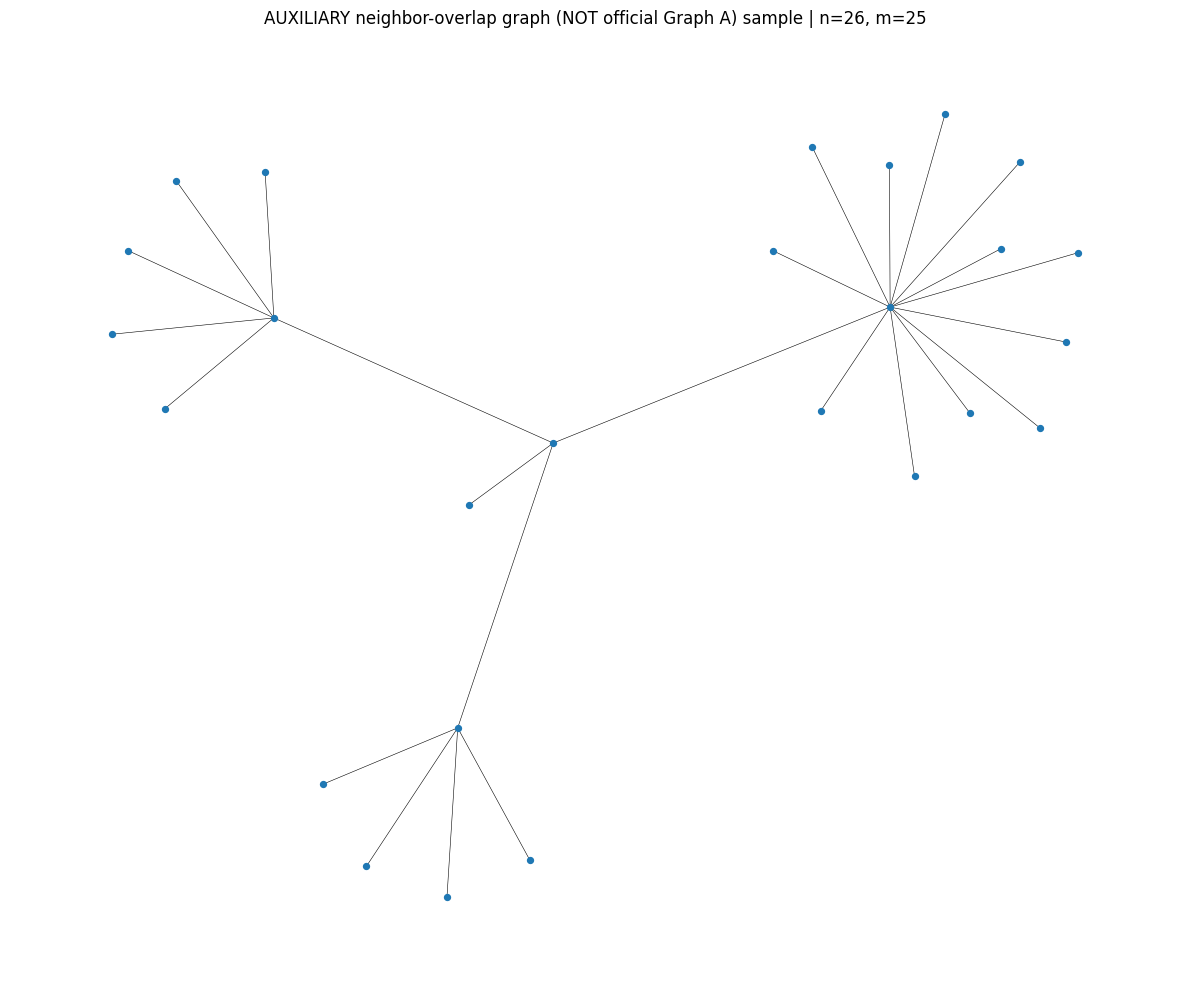

Saved: /content/drive/MyDrive/E3_member3_final_outputs/figures/auxiliary_neighbor_overlap.png


In [37]:
plot_graph = Gu

# Nếu official graph rỗng nhưng có neighbor overlap,
# chỉ minh họa auxiliary graph.
is_auxiliary = False
plot_title_prefix = 'Official Graph A'

if (
    plot_graph.number_of_edges() == 0
    and neighbor_honduras_edges
):
    Haux = nx.Graph()

    for s, t in neighbor_honduras_edges:
        Haux.add_edge(s, t)

    plot_graph = Haux
    is_auxiliary = True

    plot_title_prefix = (
        'AUXILIARY neighbor-overlap graph '
        '(NOT official Graph A)'
    )


if plot_graph.number_of_edges() > 0:

    largest = max(
        nx.connected_components(plot_graph),
        key=len
    )

    chosen = list(largest)[:250]

    H = plot_graph.subgraph(
        chosen
    ).copy()


    plt.figure(
        figsize=(12, 10)
    )

    pos = nx.spring_layout(
        H,
        seed=SEED
    )

    nx.draw_networkx(
        H,
        pos=pos,
        with_labels=False,
        node_size=18,
        width=0.4
    )

    plt.title(
        f"{plot_title_prefix} sample | "
        f"n={H.number_of_nodes()}, "
        f"m={H.number_of_edges()}"
    )

    plt.axis('off')
    plt.tight_layout()


    if is_auxiliary:
        fig_path = (
            FIG_OUT
            / 'auxiliary_neighbor_overlap.png'
        )
    else:
        fig_path = (
            FIG_OUT
            / 'interaction_graph.png'
        )


    plt.savefig(
        fig_path,
        dpi=180,
        bbox_inches='tight'
    )

    plt.show()

    print(
        "Saved:",
        fig_path
    )

else:

    print(
        "Không có edge để visualize."
    )

## 23. README bàn giao

Tự sinh README theo kết quả thực tế.


In [39]:
readme_lines = [
    "# E3 Member 3 — FINAL Handoff",
    "",
    f"Status: **{handoff_status}**",
    "",
    "## Official canonical population",
    f"- Honduras accounts: {len(canonical_ids):,}",
    "- Labels: 0=Bad, 1=Good",
    "- Splits: train / validation / test",
    "- Labels are NOT used to create graph edges.",
    "",
    "## Structured interaction data",
]

for k,v in pass1_summary['nonnull_interaction_fields'].items():
    readme_lines.append(f"- {k}: {v:,} non-null rows")

readme_lines += [
    "",
    f"- Canonical structured directed edges: {len(structured_edges_df):,}",
    "",
    "## Neighbor data provenance",
    f"- target accounts: {neighbor_audit.get('neighbor_target_accounts', 0):,}",
    f"- target overlap with Honduras: {neighbor_audit.get('target_accounts_in_honduras', 0):,}",
    f"- target overlap ratio: {neighbor_audit.get('target_overlap_ratio', 0):.4f}",
    f"- split agreement: {neighbor_audit.get('split_agreement', 0):.4f}",
    f"- auto merge allowed: {neighbor_audit.get('auto_merge_allowed', False)}",
    f"- merged into official graph: {merge_neighbor}",
    "",
    "## Official outputs",
    "- data/nodes.csv",
    "- data/interaction_edges.csv",
    "- data/interaction_edges_structured.csv",
    "- data/interaction_events.csv.gz",
    "- data/tweet_id_user_mapping.csv",
    "- data/neighbor_edges_honduras_overlap.csv",
    "- data/neighbor_edges_expanded.csv",
    "- data/graph_data_report.json",
    "- audit/data_readiness.json",
    "- graphs/interaction_graph_directed.graphml",
    "- graphs/coordination_graph.graphml",
    "- figures/interaction_graph.png (official graph, nếu có edge)",
    "- figures/auxiliary_neighbor_overlap.png (chỉ dùng khi official graph rỗng),",
    "## Important limitations",
    "- Do not infer retweet from text such as `RT @username`.",
    "- Neighbor data is not treated as Honduras unless provenance audit passes.",
    "- External support accounts do not receive Honduras labels/splits.",
    "- Zero text embedding accounts remain canonical nodes; embedding availability is a Member-4 concern.",
]

readme = "\n".join(readme_lines)
readme_path = OUT / 'README_MEMBER3_FINAL.md'
readme_path.write_text(readme, encoding='utf-8')

print(readme)
print("Saved:", readme_path)


# E3 Member 3 — FINAL Handoff

Status: **BLOCKED_NO_VALIDATED_INTERACTION_EDGES**

## Official canonical population
- Honduras accounts: 224,685
- Labels: 0=Bad, 1=Good
- Splits: train / validation / test
- Labels are NOT used to create graph edges.

## Structured interaction data

- Canonical structured directed edges: 0

## Neighbor data provenance
- target accounts: 11,826
- target overlap with Honduras: 93
- target overlap ratio: 0.0079
- split agreement: 0.4839
- auto merge allowed: False
- merged into official graph: False

## Official outputs
- data/nodes.csv
- data/interaction_edges.csv
- data/interaction_edges_structured.csv
- data/interaction_events.csv.gz
- data/tweet_id_user_mapping.csv
- data/neighbor_edges_honduras_overlap.csv
- data/neighbor_edges_expanded.csv
- data/graph_data_report.json
- audit/data_readiness.json
- graphs/interaction_graph_directed.graphml
- graphs/coordination_graph.graphml
- figures/interaction_graph.png (official graph, nếu có edge)
- figures/auxi

## 24. Final checklist

Sau khi chạy xong, folder dự kiến:

```text
E3_member3_final_outputs/
├── README_MEMBER3_FINAL.md
├── data/
│   ├── nodes.csv
│   ├── interaction_edges.csv
│   ├── interaction_edges_structured.csv
│   ├── interaction_events.csv.gz
│   ├── tweet_id_user_mapping.csv
│   ├── neighbor_edges_honduras_overlap.csv
│   ├── neighbor_edges_expanded.csv
│   └── graph_data_report.json
├── audit/
│   └── data_readiness.json
├── graphs/
│   ├── interaction_graph_directed.graphml
│   └── coordination_graph.graphml
└── figures/
    └── interaction_graph.png
```

### Bàn giao Người 4

Bắt buộc gửi:

- `nodes.csv`
- `interaction_edges.csv`
- `coordination_graph.graphml`
- `graph_data_report.json`
- `data_readiness.json`
- `README_MEMBER3_FINAL.md`

Nếu status là `BLOCKED_NO_VALIDATED_INTERACTION_EDGES`, **không được mô tả Graph A là hoàn chỉnh**. Gửi audit report cho nhóm để chốt nguồn interaction thay thế.
